# Ingeniería de características
### Objetivo y alcance
La ingeniería de caracteristicas es una etapa crucial en el preprocesado.  Es util para limpiar y obtener caracterísitcas de entrada útiles en los modelos a desarrollar.


## Construcción
### Preparación del conjunto

Parte de la ingeniería de características conlleva a aprovechar el conocimiento que se tiene sobr ela aplicación y es que los objetos a detectar son proporcionales o asociados a una persona.  
Una primer aproximación lleva a generar datos de las cabezas para calcular dimensiones relativas de los objetos:

In [ ]:
from pathlib import Path

import cv2
import pandas as pd


IMAGE_DIR = Path("../DataCapture/raw")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Ajustables: un píxel se considera "negro" si sus canales B, G y R
# están dentro de este rango.
BLACK_MAX = 40

# Filtros iniciales
MIN_WIDTH_PX = 20
MIN_HEIGHT_PX = 20
MIN_AREA_REL = 0.001
MAX_AREA_REL = 0.20
MIN_RECTANGULARITY = 0.60
MIN_ASPECT_RATIO = 0.35
MAX_ASPECT_RATIO = 2.00

rows = []

for image_path in sorted(IMAGE_DIR.iterdir()):
    if image_path.suffix.lower() not in EXTENSIONS:
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        print(f"No se pudo leer: {image_path.name}")
        continue

    image_height, image_width = image.shape[:2]
    image_area = image_width * image_height

    # Máscara blanca para píxeles cercanos al negro.
    black_mask = cv2.inRange(
        image,
        (0, 0, 0),
        (BLACK_MAX, BLACK_MAX, BLACK_MAX)
    )

    # x, y, ancho, alto y área.
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        black_mask,
        connectivity=8
    )

    
    for label in range(1, num_labels):
        x, y, w, h, pixel_area = stats[label]

        area_rel = pixel_area / image_area
        aspect_ratio = w / h if h else 0
        rectangularity = pixel_area / (w * h) if w * h else 0

        if w < MIN_WIDTH_PX or h < MIN_HEIGHT_PX:
            continue
        if not MIN_AREA_REL <= area_rel <= MAX_AREA_REL:
            continue
        if not MIN_ASPECT_RATIO <= aspect_ratio <= MAX_ASPECT_RATIO:
            continue
        if rectangularity < MIN_RECTANGULARITY:
            continue

        rows.append({
            "imagen": image_path.name,
            "head_id": sum(r["imagen"] == image_path.name for r in rows) + 1,
            "x": int(x),
            "y": int(y),
            "w": int(w),
            "h": int(h),
            "centro_x": float(centroids[label][0]),
            "centro_y": float(centroids[label][1]),
            "area_relativa": area_rel,
            "aspect_ratio": aspect_ratio,
            "rectangularidad": rectangularity,
        })

head_df = pd.DataFrame(rows)

head_df.head()
head_df.to_csv("../DataCapture/mediciones_mascara_rostro.csv", index=False)


In [ ]:
from pathlib import Path

import cv2
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

IMAGE_DIR = Path("../DataCapture/raw")
CSV_PATH = Path("../DataCapture/anotaciones.csv")

annotations = pd.read_csv(CSV_PATH)
heads = pd.read_csv("../DataCapture/mediciones_mascara_rostro.csv")
heads = heads.groupby("imagen").agg({"x": "mean", "y": "mean", "w": "mean", "h": "mean"}).reset_index()

required = {"imagen", "x", "y", "w", "h"}
missing = required - set(annotations.columns)
if missing:
    raise ValueError(f"Faltan columnas en el CSV: {sorted(missing)}")

records = []

for row in annotations.itertuples(index=False):
    image_path = IMAGE_DIR / Path(row.imagen).name
    image = cv2.imread(str(image_path))
    head_data = heads[heads["imagen"] == row.imagen]

    if image is None:
        print(f"No se pudo leer: {image_path.name}")
        continue

    #image_height, image_width = image.shape[:2]
    image_height=np.mean(head_data["h"])
    image_width=np.mean(head_data["w"])
    x, y, w, h = map(float, (row.x, row.y, row.w, row.h))

    if w <= 0 or h <= 0:
        print(f"Caja inválida en {image_path.name}")
        continue

    records.append({
        "imagen": image_path.name,  # id
        "y": y,
        "w": w,
        "h": h,
        "image_width": image_width,
        "image_height": image_height,
        "center_x_norm": (x + w / 2) / image_width,
        "center_y_norm": (y + h / 2) / image_height,
        "box_width_rel": w / image_width,
        "box_height_rel": h / image_height,
        "box_area_rel": (w * h) / (image_width * image_height),
        "box_aspect_ratio": w / h,
    })

features_df = pd.DataFrame(records)
features_df.head()


,imagen,x,y,w,h,image_width,image_height,center_x_norm,center_y_norm,box_width_rel,box_height_rel,box_area_rel,box_aspect_ratio
0,captura_20261003_153016_534962.jpg,219.0,387.0,39.0,59.0,170.0,262.0,1.402941,1.589695,0.229412,0.225191,0.051661,0.661017
1,captura_20261003_153021_540685.jpg,396.0,382.0,37.0,52.0,105.5,135.5,3.928910,3.011070,0.350711,0.383764,0.134590,0.711538
2,captura_20261003_153051_624221.jpg,259.0,203.0,11.0,14.0,104.5,90.0,2.531100,2.333333,0.105263,0.155556,0.016374,0.785714
3,captura_20261003_153056_648946.jpg,294.0,300.0,11.0,11.0,243.5,191.0,1.229979,1.599476,0.045175,0.057592,0.002602,1.000000
4,captura_20261003_153101_657504.jpg,244.0,217.0,15.0,13.0,233.5,222.5,1.077088,1.004494,0.064240,0.058427,0.003753,1.153846


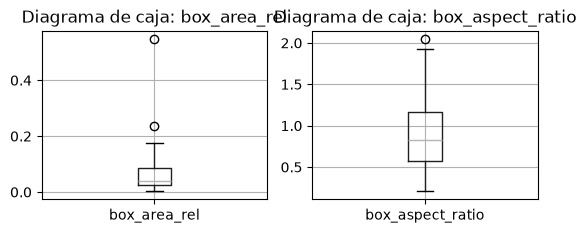

In [3]:
for col in ["box_area_rel", "box_aspect_ratio"]:
    plt.subplot(2, 2, 3 if col == "box_area_rel" else 4)
    features_df.boxplot(column=col)
    plt.title(f"Diagrama de caja: {col}")

Se observa que los objetos a encontrar respecto al tamaño de la cabena caen en escalas pequeñas y con sesgo hacia arriba, de igual manera el amontonamiento ocurre en escalas bajas.  En cuanto a la forma se observa una aproximación casi cuadrada abarcando varias geometrías.

### Generación de características

In [4]:
# Generar y extraer características útiles de las imagenes y sus anotaciones. 
# Se calculan características como el centro normalizado de la caja delimitadora, el tamaño relativo de la caja y la relación de aspecto.
# Estas características pueden ser útiles para entrenar modelos de aprendizaje automático.



In [5]:
# Limpiamos valores nulos que se meten cuando hay imagenes sin objetos detectados
features_df = features_df.dropna().reset_index(drop=True)

## Codificación y Generación de características

Se extrae la hora de captura directamente del nombre de los archivos. A partir de esto, se crea una variable categórica para indicar el turno (Tarde o Noche) y se aplica One-Hot Encoding para su uso en los modelos.

In [6]:
# Sacamos la hora del nombre (ej. captura_20261003_153016 -> 15)
features_df["hora"] = features_df["imagen"].str.extract(r"_(\d{2})\d{4}_").astype(int)

# Lo dividimos en tarde y noche
features_df["turno"] = pd.cut(features_df["hora"], bins=[0, 18, 24], labels=["Tarde", "Noche"], right=False)

# Aplicamos One-Hot Encoding
features_df = pd.get_dummies(features_df, columns=["turno"])
features_df.head()

,imagen,x,y,w,h,image_width,image_height,center_x_norm,center_y_norm,box_width_rel,box_height_rel,box_area_rel,box_aspect_ratio,hora,turno_Tarde,turno_Noche
0,captura_20261003_153016_534962.jpg,219.0,387.0,39.0,59.0,170.0,262.0,1.402941,1.589695,0.229412,0.225191,0.051661,0.661017,15,True,False
1,captura_20261003_153021_540685.jpg,396.0,382.0,37.0,52.0,105.5,135.5,3.928910,3.011070,0.350711,0.383764,0.134590,0.711538,15,True,False
2,captura_20261003_153051_624221.jpg,259.0,203.0,11.0,14.0,104.5,90.0,2.531100,2.333333,0.105263,0.155556,0.016374,0.785714,15,True,False
3,captura_20261003_153056_648946.jpg,294.0,300.0,11.0,11.0,243.5,191.0,1.229979,1.599476,0.045175,0.057592,0.002602,1.000000,15,True,False
4,captura_20261003_153101_657504.jpg,244.0,217.0,15.0,13.0,233.5,222.5,1.077088,1.004494,0.064240,0.058427,0.003753,1.153846,15,True,False


## Discretización (Binning)

Sediscretiza el área relativa de los objetos en tres categorías (Pequeño, Mediano y Grande) utilizando cuartiles, facilitando el procesamiento para algoritmos basados en reglas o árboles.

In [7]:
# Uso qcut para que queden balanceados los 3 grupos
features_df["categoria_tamano"] = pd.qcut(features_df["box_area_rel"], q=3, labels=["Pequeno", "Mediano", "Grande"])

# Codificamos a números (0, 1, 2)
features_df["tamano_codificado"] = features_df["categoria_tamano"].cat.codes
features_df[["box_area_rel", "categoria_tamano", "tamano_codificado"]].head()

,box_area_rel,categoria_tamano,tamano_codificado
0,0.051661,Mediano,1
1,0.134590,Grande,2
2,0.016374,Pequeno,0
3,0.002602,Pequeno,0
4,0.003753,Pequeno,0


## Transformación

Dado el sesgo a la derecha observado en el área de los objetos (ox_area_rel), se aplica una transformación logarítmica (log1p) para normalizar la distribución.

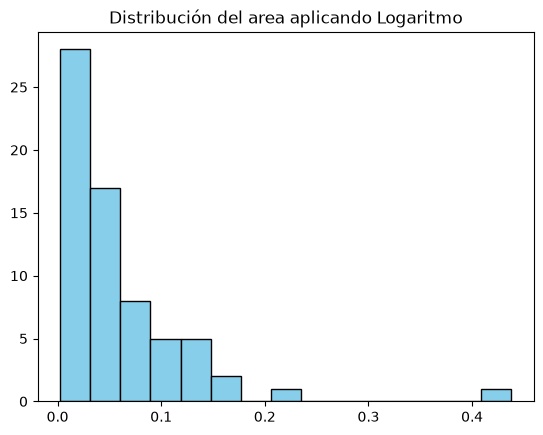

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Transformación con log1p por si hay algún cero
features_df["log_area"] = np.log1p(features_df["box_area_rel"])

plt.hist(features_df["log_area"], bins=15, color="skyblue", edgecolor="black")
plt.title("Distribución del area aplicando Logaritmo")
plt.show()

## Escalamiento

Se utiliza StandardScaler para estandarizar las características numéricas, asegurando que los modelos no sean sensibles a las distintas escalas de las dimensiones.

In [9]:
from sklearn.preprocessing import StandardScaler

# Columnas numéricas que me interesan escalar
num_cols = ["center_x_norm", "center_y_norm", "box_width_rel", "box_height_rel", "box_aspect_ratio", "log_area"]
scaler = StandardScaler()

features_scaled = features_df.copy()
features_scaled[num_cols] = scaler.fit_transform(features_df[num_cols])

features_scaled[num_cols].head()

,center_x_norm,center_y_norm,box_width_rel,box_height_rel,box_aspect_ratio,log_area
0,-1.035691,-0.326696,-0.038889,-0.108634,-0.535338,-0.157212
1,0.430924,0.773955,0.927741,0.753434,-0.421873,1.017286
2,-0.380665,0.249145,-1.028226,-0.487201,-0.255284,-0.685341
3,-1.136115,-0.319122,-1.507071,-1.019773,0.225973,-0.896462
4,-1.224886,-0.779850,-1.355140,-1.015232,0.571491,-0.878697


## Selección de características

Se evalúa la varianza y la correlación de las variables generadas para descartar redundancias.

Variables que pasaron el filtro de varianza: ['center_x_norm', 'center_y_norm', 'box_width_rel', 'box_height_rel', 'box_aspect_ratio', 'log_area']


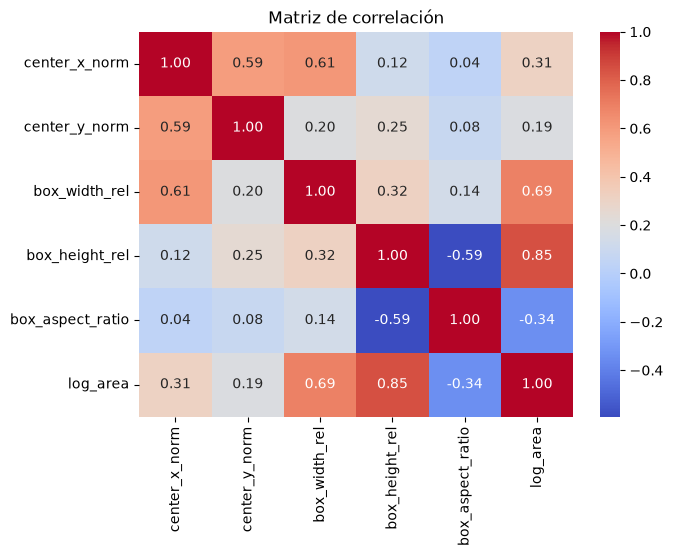

In [10]:
from sklearn.feature_selection import VarianceThreshold
import seaborn as sns

# 1. Filtro de varianza
selector = VarianceThreshold(threshold=0.01)
selector.fit(features_scaled[num_cols])
print("Variables que pasaron el filtro de varianza:", features_scaled[num_cols].columns[selector.get_support()].tolist())

# 2. Correlación
corr = features_scaled[num_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

Al observar el mapa de calor, se identifica una alta correlación entre las proporciones (ancho/alto) y el área logarítmica, lo que justifica aplicar técnicas de reducción de dimensionalidad.

## Extracción de características (PCA)

Se aplica el Análisis de Componentes Principales (PCA) para reducir la dimensionalidad de las proporciones y tamaños, consolidando la información en dos componentes principales.

Porcentaje de info (varianza) explicada: 73.75378894227018 %


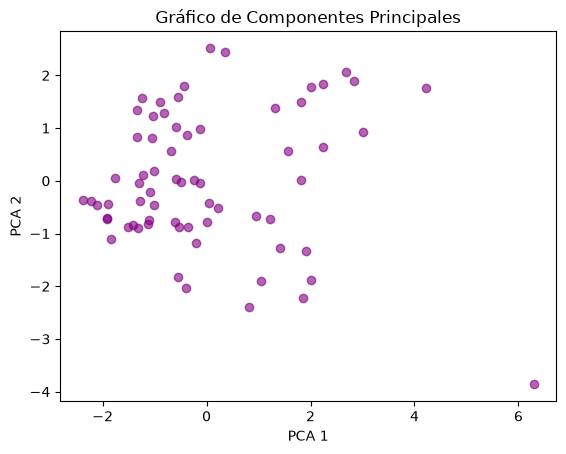

In [11]:
from sklearn.decomposition import PCA

# Lo reduzco a 2 componentes
pca = PCA(n_components=2)
pca_datos = pca.fit_transform(features_scaled[num_cols])

features_scaled["PCA1"] = pca_datos[:, 0]
features_scaled["PCA2"] = pca_datos[:, 1]

print("Porcentaje de info (varianza) explicada:", pca.explained_variance_ratio_.sum() * 100, "%")

plt.scatter(features_scaled["PCA1"], features_scaled["PCA2"], color="purple", alpha=0.6)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Gráfico de Componentes Principales")
plt.show()

## Conclusiones (Fase de Preparación de datos según CRISP-ML)

En esta etapa se transformaron los datos crudos en un conjunto estructurado y listo para el modelado. Las acciones principales incluyen:
- Extracción y codificación temporal (turnos).
- Transformaciones logarítmicas para mitigar el sesgo en tamaños de objetos.
- Estandarización de variables para facilitar la convergencia paramétrica.
- Reducción de ruido y colinealidad mediante PCA.

El dataset resultante cumple con los requerimientos de calidad para iniciar la experimentación y validación de modelos predictivos.